In [1]:
import pandas as pd
from pipeline import IndicatorSpec, build_feature_df
from data import fetch_binance_klines
from simulation.rules import Rule, RuleGroup, ALL, ANY
from simulation.rule_features import add_last_n_compare, add_cross_compare
from simulation.simulator import Strategy, SimConfig, run_simulation, align_timeframes
from plot_simulation import plot_simulation
from plotter import plot_interactive, PlotConfig, IndicatorSpec
from mtf_plot import make_plot_indicators, assert_plot_columns_exist
from features.ema_spreads import EmaSpreadSpec, add_ema_spread_features
from features.cross_through import CrossThroughSpec, add_cross_through_features
from simulation.rules import Ctx
from analytics import (
    trades_to_frame,
    plot_balance_by_trade,
    plot_trade_pnl_bars,
    trade_summary_table
)
from plot_toggles import (
    PlotToggle,
    make_plot_indicators_from_toggles,
    assert_plot_columns_exist,
)

from ema_diagnostic_plots import (
    ema_pair_spread_panel,
    ema_group_spread_panel,
    ema_cut_through_panel,
)
from simulation.simulator import (
    TradeExitConfig,
    StopLossConfig,
    PositionSizingConfig,
    TakeProfitConfig,
)

In [2]:
symbol = "BTCUSDT"
market = "spot"
tz = "Asia/Karachi"

# Start earlier for EMA warmup.
fetch_start = "2026-01-01"
sim_start = "2026-05-06"
end = None

In [3]:
# ============================================================
# RSI Configs
# ============================================================

RSI_DIV_CFG = {
    "length": 14,
    "pivot_lookback": 5,
    "min_rsi_delta": 2,

    # divergence filtering
    "os_level": 30,
    "ob_level": 70,
    "zone_mode": "cross",

    # panel styling
    "major_levels": [30, 70],
    "minor_levels": [20, 80],
    "show_zone_shading": True,

    # divergence labels
    "show_div_labels": True,
    "max_div_labels": 6,
    "label_font_size": 10,
    "label_xshift": 10,
    "label_yshift": 14,

    # main chart markers
    "mark_price": True,
    "price_marker_size": 18,
    "marker_offset_mult": 1.35,
}

# ============================================================
# Supertrend Configs
# ============================================================

ST1_1M_CFG = {
    "length": 21,
    "multiplier": 1.0,
    "show_markers": True,
}

ST1_5M_CFG = {
    "length": 21,
    "multiplier": 1.0,
    "show_markers": True,
}

ST1_15M_CFG = {
    "length": 21,
    "multiplier": 1.0,
    "show_markers": True,
}

ST2_1M_CFG = {
    "length": 14,
    "multiplier": 2.0,
    "show_markers": True,
}

ST2_5M_CFG = {
    "length": 14,
    "multiplier": 2.0,
    "show_markers": True,
}

ST2_15M_CFG = {
    "length": 14,
    "multiplier": 2.0,
    "show_markers": True,
}


# ============================================================
# Supertrend Tags
# ============================================================

ST1_TAG = "st1_21_1"
ST2_TAG = "st2_14_2"

In [4]:
### 1 Minute Indicators ###
EMA50_1m = "1m__ema__EMA_50"
EMA100_1m = "1m__ema__EMA_100"
EMA150_1m = "1m__ema__EMA_150"
EMA200_1m = "1m__ema__EMA_200"
MACD_1M = "1m__macd_8_21_5__MACD"
MACD_SIGNAL_1M = "1m__macd_8_21_5__SIGNAL"
MACD_HIST_1M = "1m__macd_8_21_5__HIST"
BULL_DIV_1m = "1m__rsi14__BULL_DIV"
BEAR_DIV_1m = "1m__rsi14__BEAR_DIV"
BULL_START_RSI_1m = "1m__rsi14__BULL_START_RSI"
BEAR_START_RSI_1m = "1m__rsi14__BEAR_START_RSI"

### 5 Minute Indicators ###
EMA50_5m = "5m__ema__EMA_50"
EMA75_5m = "5m__ema__EMA_75"
EMA100_5m = "5m__ema__EMA_100"
EMA125_5m = "5m__ema__EMA_125"
EMA150_5m = "5m__ema__EMA_150"
EMA175_5m = "5m__ema__EMA_175"
EMA200_5m = "5m__ema__EMA_200"
MACD_5M = "5m__macd_8_21_5__MACD"
MACD_SIGNAL_5M = "5m__macd_8_21_5__SIGNAL"
MACD_HIST_5M = "5m__macd_8_21_5__HIST"
BULL_DIV_5m = "5m__rsi14__BULL_DIV"
BEAR_DIV_5m = "5m__rsi14__BEAR_DIV"
BULL_START_RSI_5m = "5m__rsi14__BULL_START_RSI"
BEAR_START_RSI_5m = "5m__rsi14__BEAR_START_RSI"

### 15 Minute Indicators ###
EMA50_15m = "15m__ema__EMA_50"
EMA75_15m = "15m__ema__EMA_75"
EMA100_15m = "15m__ema__EMA_100"
EMA125_15m = "15m__ema__EMA_125"
EMA150_15m = "15m__ema__EMA_150"
EMA175_15m = "15m__ema__EMA_175"
EMA200_15m = "15m__ema__EMA_200"
MACD_15M = "15m__macd_8_21_5__MACD"
MACD_SIGNAL_15M = "15m__macd_8_21_5__SIGNAL"
MACD_HIST_15M = "15m__macd_8_21_5__HIST"
BULL_DIV_15m = "15m__rsi14__BULL_DIV"
BEAR_DIV_15m = "15m__rsi14__BEAR_DIV"
BULL_START_RSI_15m = "15m__rsi14__BULL_START_RSI"
BEAR_START_RSI_15m = "15m__rsi14__BEAR_START_RSI"


In [5]:
# ============================================================
# 1m indicators
# ============================================================

ind_1m = [
    IndicatorSpec("moving_average", tag="ema", config={
        "type": "ema",
        "periods": [50, 100, 150, 200, 250],
        "source": "close",
    }),

    IndicatorSpec("macd", tag="macd_8_21_5", config={
        "fast": 8,
        "slow": 21,
        "signal": 5,
    }),

    IndicatorSpec("rsi_divergence", tag="rsi14", config=RSI_DIV_CFG),

    IndicatorSpec("supertrend", tag=ST1_TAG, config=ST1_1M_CFG),
    IndicatorSpec("supertrend", tag=ST2_TAG, config=ST2_1M_CFG),
]


# ============================================================
# 5m indicators
# ============================================================

ind_5m = [
    IndicatorSpec("moving_average", tag="ema", config={
        "type": "ema",
        "periods": [50, 75, 100, 125, 150, 175, 200],
        "source": "close",
    }),

    IndicatorSpec("macd", tag="macd_8_21_5", config={
        "fast": 8,
        "slow": 21,
        "signal": 5,
    }),

    IndicatorSpec("rsi_divergence", tag="rsi14", config=RSI_DIV_CFG),

    IndicatorSpec("supertrend", tag=ST1_TAG, config=ST1_5M_CFG),
    IndicatorSpec("supertrend", tag=ST2_TAG, config=ST2_5M_CFG),
]


# ============================================================
# 15m indicators
# ============================================================

ind_15m = [
    IndicatorSpec("moving_average", tag="ema", config={
        "type": "ema",
        "periods": [50, 75, 100, 125, 150, 175, 200],
        "source": "close",
    }),

    IndicatorSpec("macd", tag="macd_8_21_5", config={
        "fast": 8,
        "slow": 21,
        "signal": 5,
    }),

    IndicatorSpec("rsi_divergence", tag="rsi14", config=RSI_DIV_CFG),

    IndicatorSpec("supertrend", tag=ST1_TAG, config=ST1_15M_CFG),
    IndicatorSpec("supertrend", tag=ST2_TAG, config=ST2_15M_CFG),
]

In [6]:
# 1m base data
df1 = fetch_binance_klines(
    symbol=symbol,
    interval="1m",
    start=fetch_start,
    end=end,
    market=market,
    cache=True,
    cache_dir="data",
)

df1_feat, _, _ = build_feature_df(
    raw_df=df1,
    tz=tz,
    ma_windows=[],
    indicators=ind_1m,
)


# 5m filter data
df5 = fetch_binance_klines(
    symbol=symbol,
    interval="5m",
    start=fetch_start,
    end=end,
    market=market,
    cache=True,
    cache_dir="data",
)

df5_feat, _, _ = build_feature_df(
    raw_df=df5,
    tz=tz,
    ma_windows=[],
    indicators=ind_5m,
)


# 15m filter data
df15 = fetch_binance_klines(
    symbol=symbol,
    interval="15m",
    start=fetch_start,
    end=end,
    market=market,
    cache=True,
    cache_dir="data",
)

df15_feat, _, _ = build_feature_df(
    raw_df=df15,
    tz=tz,
    ma_windows=[],
    indicators=ind_15m,
)

merged = align_timeframes(
    base_df=df1_feat,
    other_dfs={
        "5m": df5_feat,
        "15m": df15_feat,
    },
    base_label="1m",
)


[18:24:46] INFO | 01. Parameters: market=spot, symbol=BTCUSDT, interval=1m, start=2026-01-01 00:00:00+00:00, end=LATEST
[18:24:46] INFO | 02. Cache directory: C:\Users\Talal Zahid\Desktop\Talal\Binance\data (cwd=C:\Users\Talal Zahid\Desktop\Talal\Binance)
[18:24:46] INFO | 03. Main cache file: C:\Users\Talal Zahid\Desktop\Talal\Binance\data\binance_spot_BTCUSDT_1m.parquet
[18:24:46] INFO | 04. Partial checkpoint dir: C:\Users\Talal Zahid\Desktop\Talal\Binance\data\.partials\binance_spot_BTCUSDT_1m
[18:24:46] INFO | 05. Cache: HIT | rows=203,007 (main_rows=203,007, partial_files=0) | range=2026-01-01 00:00:00+00:00 -> 2026-05-21 23:26:00+00:00
[18:24:46] INFO | 06. Fetch plan 1/1: 2026-05-21 23:27:00+00:00 -> LATEST
[18:24:46] INFO | 07. Starting fetch range 1/1.


BTCUSDT 1m: 0page [00:00, ?page/s]

[18:24:48] INFO | 08. Completed fetch range 1/1 | rows=838 | total_rows_fetched=838 | requests=1 | retries=0 | elapsed=1.7s
[18:24:48] INFO | 09. Cache consolidated and saved (parquet) | rows=203,845 | range=2026-01-01 00:00:00+00:00 -> 2026-05-22 13:24:00+00:00 | cleared_partial_files=1
[18:24:48] INFO | 10. Fetch summary | new_rows=838 | successful_pages=1 | requests=1 | retries=0 | partial_saves=1 | elapsed=2.1s
[18:24:48] INFO | 11. Returning slice | rows=203,845 | range=2026-01-01 00:00:00+00:00 -> 2026-05-22 13:24:00+00:00
[18:28:14] INFO | 01. Parameters: market=spot, symbol=BTCUSDT, interval=5m, start=2026-01-01 00:00:00+00:00, end=LATEST
[18:28:14] INFO | 02. Cache directory: C:\Users\Talal Zahid\Desktop\Talal\Binance\data (cwd=C:\Users\Talal Zahid\Desktop\Talal\Binance)
[18:28:14] INFO | 03. Main cache file: C:\Users\Talal Zahid\Desktop\Talal\Binance\data\binance_spot_BTCUSDT_5m.parquet
[18:28:14] INFO | 04. Partial checkpoint dir: C:\Users\Talal Zahid\Desktop\Talal\Binance\d

BTCUSDT 5m: 0page [00:00, ?page/s]

[18:28:15] INFO | 08. Completed fetch range 1/1 | rows=167 | total_rows_fetched=167 | requests=1 | retries=0 | elapsed=0.8s
[18:28:16] INFO | 09. Cache consolidated and saved (parquet) | rows=145,890 | range=2025-01-01 00:00:00+00:00 -> 2026-05-22 13:25:00+00:00 | cleared_partial_files=1
[18:28:16] INFO | 10. Fetch summary | new_rows=167 | successful_pages=1 | requests=1 | retries=0 | partial_saves=1 | elapsed=1.2s
[18:28:16] INFO | 11. Returning slice | rows=40,770 | range=2026-01-01 00:00:00+00:00 -> 2026-05-22 13:25:00+00:00
[18:28:57] INFO | 01. Parameters: market=spot, symbol=BTCUSDT, interval=15m, start=2026-01-01 00:00:00+00:00, end=LATEST
[18:28:57] INFO | 02. Cache directory: C:\Users\Talal Zahid\Desktop\Talal\Binance\data (cwd=C:\Users\Talal Zahid\Desktop\Talal\Binance)
[18:28:57] INFO | 03. Main cache file: C:\Users\Talal Zahid\Desktop\Talal\Binance\data\binance_spot_BTCUSDT_15m.parquet
[18:28:57] INFO | 04. Partial checkpoint dir: C:\Users\Talal Zahid\Desktop\Talal\Binance\

BTCUSDT 15m: 0page [00:00, ?page/s]

[18:28:58] INFO | 08. Completed fetch range 1/1 | rows=55 | total_rows_fetched=55 | requests=1 | retries=0 | elapsed=0.8s
[18:28:58] INFO | 09. Cache consolidated and saved (parquet) | rows=13,590 | range=2026-01-01 00:00:00+00:00 -> 2026-05-22 13:15:00+00:00 | cleared_partial_files=1
[18:28:58] INFO | 10. Fetch summary | new_rows=55 | successful_pages=1 | requests=1 | retries=0 | partial_saves=1 | elapsed=0.9s
[18:28:58] INFO | 11. Returning slice | rows=13,590 | range=2026-01-01 00:00:00+00:00 -> 2026-05-22 13:15:00+00:00


In [7]:
# ============================================================
# Helper to build Supertrend column names
# ============================================================

def st_cols(tf: str, tag: str) -> dict:
    root = f"{tf}__{tag}"
    return {
        "ST": f"{root}__ST",
        "DIR": f"{root}__DIR",
        "BUY": f"{root}__BUY",
        "SELL": f"{root}__SELL",
        "BUY_LINE": f"{root}__ST_BUY_LINE",
        "SELL_LINE": f"{root}__ST_SELL_LINE",
    }


# ============================================================
# ST1 aliases: length 21, multiplier 1.0
# ============================================================

ST1_1M = st_cols("1m", ST1_TAG)
ST1_5M = st_cols("5m", ST1_TAG)
ST1_15M = st_cols("15m", ST1_TAG)


# ============================================================
# ST2 aliases: length 14, multiplier 2.0
# ============================================================

ST2_1M = st_cols("1m", ST2_TAG)
ST2_5M = st_cols("5m", ST2_TAG)
ST2_15M = st_cols("15m", ST2_TAG)


In [8]:
[c for c in merged.columns if "supertrend" in c.lower()]

[]

In [9]:
N_CONFIRM = 1               # number of consecutive confirmation candles required
MAX_WAIT_AFTER_CROSS = 30   # how many candles after the cross we are willing to wait
MACD_THRESHOLD_1M = 100
MACD_THRESHOLD_5M = 10
MACD_THRESHOLD_15M = 10 

MIN_MACD_DIFF_1M = 5
MIN_MACD_DIFF_5M = 5
MIN_MACD_DIFF_15M = 5

DIV_LOOKBACK = 5

N_SPREAD_CONFIRM = 3
MIN_SPREAD_PCT = 0.1

MIN_EMAS_CROSSED = 4
CROSS_LOOKBACK = 40


#####################################################################################


LONG_EMA_FILTERS = [
    # EMA50_1m,
    # EMA100_1m,
    # EMA150_1m,
    # EMA200_1m,
    # EMA100_5m,
    # EMA200_5m,
    # EMA100_15m,
    EMA200_15m
]


macd_rules = ALL(
    Rule(
        "1m MACD above threshold",
        lambda c: c.gt(MACD_1M, 10)
    ),
    
    # Rule(
    #     "5m MACD above threshold",
    #     lambda c: c.gt(MACD_5M, MACD_THRESHOLD_5M)
    # ),
    
    # Rule(
    #     "15m MACD above threshold",
    #     lambda c: c.gt(MACD_15M, MACD_THRESHOLD_15M)
    # ),

    Rule(
        "1m MACD - Signal above minimum",
        lambda c: c.gt(MACD_HIST_1M, 50)
    ),
    
    Rule(
         "5m MACD - Signal above minimum",
         lambda c: c.gt(MACD_HIST_5M, 20)
     ),

    Rule(
        "15m MACD - Signal above minimum",
        lambda c: c.gt(MACD_HIST_15M, 20)
    ),
    
)

supertrend_long_filter_strict = ALL(
    # Rule("ST1 1m bullish", lambda c: c.gt(ST1_1M["DIR"], 0)),
    # Rule("ST1 5m bullish", lambda c: c.gt(ST1_1M["DIR"], 0)),
    Rule("ST1 15m bullish", lambda c: c.gt(ST1_15M["DIR"], 0)),

    # Rule("ST2 1m bullish", lambda c: c.gt(ST2_1M["DIR"], 0)),
    # Rule("ST2 5m bullish", lambda c: c.gt(ST2_1M["DIR"], 0)),
    Rule("ST2 15m bullish", lambda c: c.gt(ST2_15M["DIR"], 0)),
)

open_rules_long = ALL(
    supertrend_long_filter_strict,
    macd_rules,
    Rule(
        "Current close above all EMA filters",
        lambda c: c.close_above_all(LONG_EMA_FILTERS)

),
    Rule(
        f"Last {N_CONFIRM} candles green",
        lambda c: c.consecutive_green(n=N_CONFIRM)
    ),
)

close_rules_long = ALL(
    # Rule(
    #     "ST1 1m bearish",
    #     lambda c: c.lt(ST1_15M["DIR"], 0)
    # ),
    Rule(
        "ST2 5m bearish",
        lambda c: c.lt(ST2_5M["DIR"], 0)
    ),
)



###################### short rules #########################


In [10]:
strategy = Strategy(
    open_rules_long=open_rules_long,
    close_rules_long=close_rules_long,
)

# res = run_simulation(
#     df=merged,
#     strategy=strategy,
#     cfg=SimConfig(
#         initial_cash=10_000,
#         max_open_trades=1,
#         fee_bps=10,
#         slippage_bps=1,
#         # sim_start=sim_start,
#         sim_start="2026-01-01",
#         sim_end="2026-05-18",
#         #sim_start="2026-05-10",
#         #sim_end="2026-05-15",
#         sim_tz=tz,
#     ),
#     time_col="t",
#     price_col="close",
# )

from simulation.simulator import (
    SimConfig,
    TradeExitConfig,
    StopLossConfig,
    PositionSizingConfig,
    TakeProfitConfig,
)

cfg = SimConfig(
    initial_cash=10_000,
    max_open_trades=1,
    fee_bps=10,
    slippage_bps=1,

    sim_start="2026-01-01",
    sim_end="2026-05-18",
    sim_tz=tz,

    exit=TradeExitConfig(
        enabled=True,
        # Important:
        # if both TP and SL are touched in same candle, assume SL first
        intrabar_priority="stop_first",
        # Important:
        # disables ST2 close rule while TP/SL system is active
        allow_rule_close=False,
        
        # stop_loss=StopLossConfig(
        #     mode="entry_pct",
        #     value=1,   # 0.5% below entry for long
        # ),

        # sizing=PositionSizingConfig(
        #     mode="cash",  # use normal full cash sizing
        # ),

        # take_profits=(
        #     TakeProfitConfig(
        #         label="TP1",
        #         mode="entry_pct",
        #         value=2,       # +1.0%
        #         close_pct=100.0, # close full trade
        #     ),
        # ),
        stop_loss=StopLossConfig(
            mode="entry_pct",
            value=0.5,   # 0.5% below entry for long
        ),
        sizing=PositionSizingConfig(
            mode="cash",  # use normal full cash sizing
        ),
        take_profits=(
            TakeProfitConfig(
                label="TP1",
                mode="entry_pct",
                value=0.5,          # +0.5%
                close_pct=50.0,     # close 50% of remaining
                move_stop_mode="breakeven",
            ),

            TakeProfitConfig(
                label="TP2",
                mode="entry_pct",
                value=1,          # +1.0%
                close_pct=100.0,    # close rest
            ),
        ),
    ),
)

res = run_simulation(
    df=merged,
    strategy=strategy,
    cfg=cfg,
    time_col="t",
    price_col="close",
)

res.stats #, res.events.head(), res.equity_curve.tail()

[18:29:17] INFO | Simulation window applied | rows=198,420/203,845 | range=2026-01-01 05:00:00+05:00 -> 2026-05-18 23:59:00+05:00


Simulation:   0%|          | 0/198420 [00:00<?, ?bar/s]

[18:29:17] INFO | Simulation started | bars=198,420 | initial_cash=10,000.00 | cash_per_trade=10,000.00 | max_open_trades=1 | fee_bps=10 | slippage_bps=1 | exit_enabled=True
[18:29:35] INFO | Simulation finished | elapsed=19.16s | bars=198,420 | opened=32 | closed=32 | final_cash=9,252.65 | total_return=-7.47% | max_dd=8.14%


{'initial_cash': 10000.0,
 'final_cash': 9252.648900340366,
 'total_pnl': -747.3510996596337,
 'total_return_pct': -7.473510996596344,
 'num_trades': 32.0,
 'num_winners': 16.0,
 'num_losers': 16.0,
 'num_breakeven': 0.0,
 'win_rate_pct': 50.0,
 'loss_rate_pct': 50.0,
 'gross_profit': 347.6769229380091,
 'gross_loss': 1095.028022597643,
 'profit_factor': 0.3175050462299991,
 'avg_pnl': -23.354721864363555,
 'median_pnl': -31.20483707472622,
 'avg_winner': 21.72980768362557,
 'avg_loser': -68.43925141235269,
 'avg_loser_abs': 68.43925141235269,
 'largest_winner': 53.17745481152264,
 'largest_loser': -70.9440050000011,
 'payoff_ratio': 0.3175050462299991,
 'expectancy_per_trade': -23.354721864363555,
 'expectancy_pct_initial_cash': -0.23354721864363553,
 'avg_return_pct': -0.2412056281250003,
 'median_return_pct': -0.3348525124999941,
 'best_return_pct': 0.5391850750000047,
 'worst_return_pct': -0.7094400500000126,
 'avg_duration_min': 32.34375,
 'median_duration_min': 22.5,
 'avg_bars_h

In [11]:
trade_summary_table(res.trades, initial_cash=10_000, interval="1m")

,trade_no,trade_id,side,entry_time,exit_time,entry_price,exit_price,qty,pnl,return_pct,duration_min,candle_count,balance,open_reason,close_reason
1,1,1.0,long,2026-01-05 19:45:00+05:00,2026-01-05 20:22:00+05:00,93316.320699,93306.989067,0.107162,3.973503,-0.01000,37.0,37.0,10003.973503,"ST1 15m bullish, ST2 15m bullish, 1m MACD abov...",STOP_LOSS
2,2,2.0,long,2026-01-09 20:31:00+05:00,2026-01-09 20:44:00+05:00,91679.577041,91212.057038,0.109076,-70.944005,-0.50995,13.0,13.0,9933.029497,"ST1 15m bullish, ST2 15m bullish, 1m MACD abov...",STOP_LOSS
3,3,3.0,long,2026-01-12 06:05:00+05:00,2026-01-12 06:34:00+05:00,91719.171000,91251.449087,0.108298,-70.468889,-0.50995,29.0,29.0,9862.560608,"ST1 15m bullish, ST2 15m bullish, 1m MACD abov...",STOP_LOSS
4,4,4.0,long,2026-01-13 20:35:00+05:00,2026-01-13 23:47:00+05:00,92859.274999,93778.488962,0.106210,53.177455,0.98990,192.0,192.0,9915.738063,"ST1 15m bullish, ST2 15m bullish, 1m MACD abov...",TAKE_PROFIT_FULL
5,5,5.0,long,2026-01-14 19:47:00+05:00,2026-01-14 20:39:00+05:00,96407.979834,96398.339036,0.102852,3.940021,-0.01000,52.0,52.0,9919.678084,"ST1 15m bullish, ST2 15m bullish, 1m MACD abov...",STOP_LOSS
6,6,6.0,long,2026-01-28 22:54:00+05:00,2026-01-28 23:00:00+05:00,90478.196915,90016.803350,0.109636,-70.374169,-0.50995,6.0,6.0,9849.303915,"ST1 15m bullish, ST2 15m bullish, 1m MACD abov...",STOP_LOSS
7,7,7.0,long,2026-02-02 20:40:00+05:00,2026-02-02 20:51:00+05:00,79237.242932,78833.172612,0.124301,-69.874907,-0.50995,11.0,11.0,9779.429008,"ST1 15m bullish, ST2 15m bullish, 1m MACD abov...",STOP_LOSS
8,8,8.0,long,2026-02-06 21:10:00+05:00,2026-02-06 21:25:00+05:00,69434.852791,69427.909306,0.140843,3.885859,-0.01000,15.0,15.0,9783.314867,"ST1 15m bullish, ST2 15m bullish, 1m MACD abov...",STOP_LOSS
9,9,9.0,long,2026-02-06 22:32:00+05:00,2026-02-06 22:34:00+05:00,71485.727858,71121.186389,0.136857,-69.406754,-0.50995,2.0,2.0,9713.908113,"ST1 15m bullish, ST2 15m bullish, 1m MACD abov...",STOP_LOSS
10,10,10.0,long,2026-02-07 17:19:00+05:00,2026-02-07 17:20:00+05:00,69871.736475,69515.425555,0.139025,-68.914355,-0.50995,1.0,1.0,9644.993758,"ST1 15m bullish, ST2 15m bullish, 1m MACD abov...",STOP_LOSS


In [12]:
# plot_indicators = make_plot_indicators(
#     base_specs=ind_1m,
#     mtf_specs={
#         "5m": ind_5m,
#         "15m": ind_15m,
#     },
#     mtf_include={
#         "5m": ["macd_8_21_5"],
#         "15m": ["macd_8_21_5"],
#     }
# )

In [13]:
indicators_by_tf = {
    "1m": ind_1m,
    "5m": ind_5m,
    "15m": ind_15m,
}


plot_toggles = [
    # Optional EMA overlays
    PlotToggle("1m", "ema", visible="legendonly"),
    PlotToggle("5m", "ema", visible="legendonly"),
    PlotToggle("15m", "ema", visible="legendonly"),

    # Supertrend setting 1
    PlotToggle("1m", ST1_TAG, visible="legendonly"),
    PlotToggle("5m", ST1_TAG, visible="legendonly"),
    PlotToggle("15m", ST1_TAG, visible="legendonly"),

    # Supertrend setting 2
    PlotToggle("1m", ST2_TAG, visible="legendonly"),
    PlotToggle("5m", ST2_TAG, visible="legendonly"),
    PlotToggle("15m", ST2_TAG, visible="legendonly"),

    # Hide MACD
    PlotToggle("1m", "macd_8_21_5",  visible="legendonly"),
    PlotToggle("5m", "macd_8_21_5",  visible="legendonly"),
    PlotToggle("15m", "macd_8_21_5",  visible="legendonly"),

    # Hide RSI
    PlotToggle("1m", "rsi14", visible=False),
    PlotToggle("5m", "rsi14", visible=False),
    PlotToggle("15m", "rsi14", visible=False),
]

plot_indicators = make_plot_indicators_from_toggles(
    indicators_by_tf=indicators_by_tf,
    toggles=plot_toggles,
)

assert_plot_columns_exist(merged, plot_indicators)


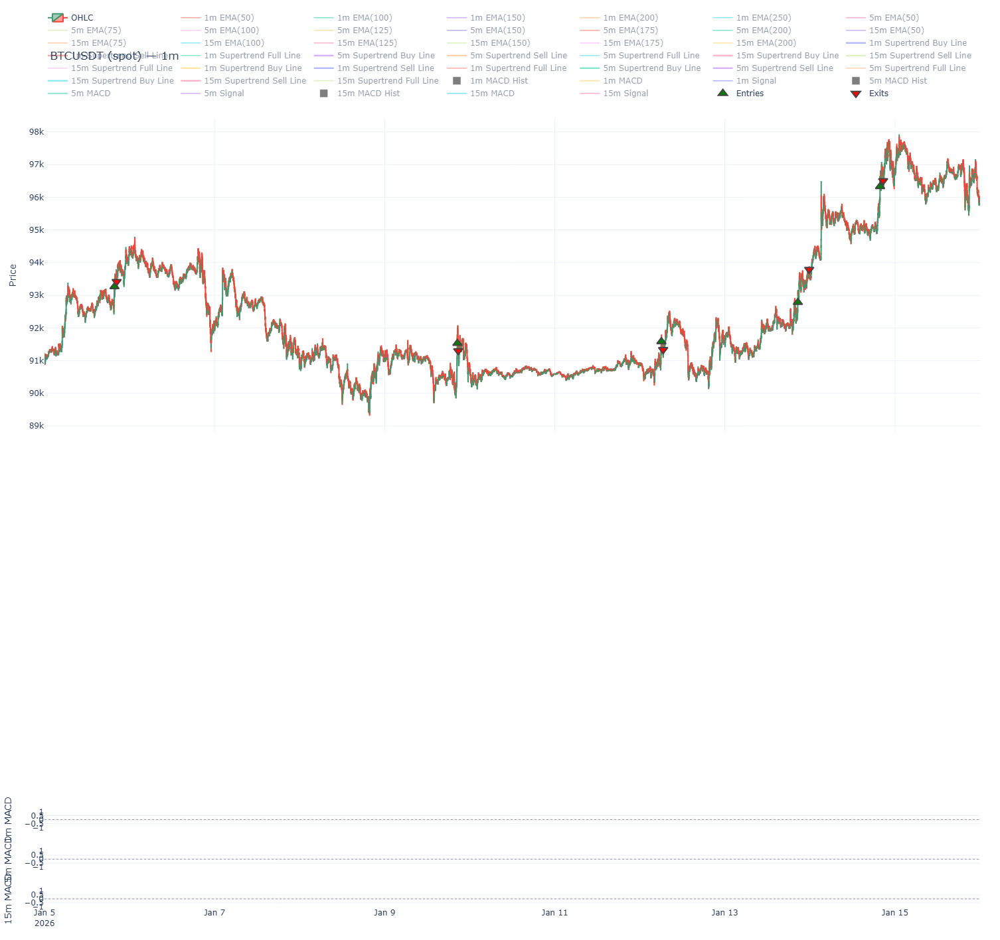

In [14]:
plot_simulation(
    df_raw=merged,
    symbol=symbol,
    interval="1m",
    market=market,
    trades=res.trades,
    ma_windows=[],
    indicators=plot_indicators,
    plot_cfg=PlotConfig(
        tz=tz,
        # date_from="2026-05-06",
        # date_to="2026-05-10",
        date_from="2026-1-05",
        date_to="2026-1-16",
        height=1400,
        width=1900,
    ),
)

# plot_simulation(
#     df_raw=df1_feat,  # (ideally raw candles df; but if yours works as-is, ok)
#     symbol=symbol,
#     interval="5m",
#     market=market,
#     trades=res.trades,
#     ma_windows=[20],
#     indicators=ind_5m,
#     plot_cfg=PlotConfig(
#         tz="Asia/Karachi",
#         date_from="2026-02-01",
#         date_to="2026-02-05",
#         height=1400,
#         width=1900
#     ),
# )